In [1]:
# ---------------------------------------------------------
# Part 1 Code: Import Required Libraries
# ---------------------------------------------------------

# pandas: for tabular data manipulation, date parsing, and time series indexing
import pandas as pd

# numpy: for numerical array operations, math formulas, and repetition/tiling
import numpy as np

# matplotlib.pyplot: for creating clean visualizations and time series plots
import matplotlib.pyplot as plt

# time: for benchmarking how long SARIMA takes to fit
from time import time

# os: for robust file path handling across different working directories (local repo vs Colab)
import os

# SARIMAX: statsmodels implementation for fitting Seasonal Autoregressive Integrated Moving Average
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Ensure pandas datetime converters are registered for clean matplotlib date formatting
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()


## Part 2: Prepare the Bicycle Dataset & Data Checking

### Dataset Context & Operational Scope:
- We utilize `day.csv` from the UCI Machine Learning Repository Bike Sharing Dataset.
- Target series: `dteday` (calendar date) and `cnt` (total daily rental count across the recorded system).
- **Critical Operational Distinction:**
  - `cnt` is the daily aggregate rental count across the **entire metropolitan system**.
  - It does **not** represent unique people (a single commuter can rent a bike twice in one day).
  - It does **not** represent individual bicycle availability or dock capacity at any specific station.
- **Univariate Formulation:**
  - We use **only** the dated `cnt` series as input.
  - Other fields (such as `casual`, `registered`, `temp`, `hum`, `windspeed`, or `weathersit`) are excluded.
  


In [2]:
# ---------------------------------------------------------
# Part 2 Code (Step 1): Load day.csv with Robust Path Handling
# ---------------------------------------------------------

# Check if file is located in '../data/raw/day.csv' (local repo) or 'day.csv' (Google Colab upload)
csv_path = "../data/raw/day.csv" if os.path.exists("../data/raw/day.csv") else "day.csv"

# Load CSV and parse 'dteday' column directly as datetime objects
df = pd.read_csv(csv_path, parse_dates=["dteday"])

# Sort strictly in chronological order and reset row index to guarantee ordered sequence
df = df.sort_values("dteday").reset_index(drop=True)

# Display dataset dimensions and initial preview
print(f"Loaded dataset from '{csv_path}' successfully.")
print("Dataset dimensions (rows, columns):", df.shape)
df.head()


Loaded dataset from '../data/raw/day.csv' successfully.
Dataset dimensions (rows, columns): (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Data Integrity Checks Table
To guarantee our time series has no missing dates, duplicates, or corrupted counts, we construct an explicit 9-point validation table comparing observed results against expected values.


In [3]:
# ---------------------------------------------------------
# Part 2 Code (Step 2): Build 9-Point Data Integrity Checks Table
# ---------------------------------------------------------

# Creates a reference calendar of all 731 days that should exist between Jan 1, 2011 and Dec 31, 2012
full_range = pd.date_range("2011-01-01", "2012-12-31", freq="D")

# Sort dates chronologically so we can inspect the exact first and last date
sorted_dates = df["dteday"].sort_values()

# Compile the 9 required integrity checks into a clear DataFrame
checks = pd.DataFrame({
    "check": [
        "Rows",
        "First date",
        "Last date",
        "Missing dteday values",
        "Duplicate dates",
        "Missing calendar days",
        "Missing cnt",
        "Negative cnt",
        "Non-integer cnt"
    ],
    "result": [
        len(df),                                                     # Counts total rows in the dataset
        str(sorted_dates.iloc[0].date()),                            # Grabs the first date in the dataset
        str(sorted_dates.iloc[-1].date()),                           # Grabs the last date in the dataset
        df["dteday"].isna().sum(),                                   # Counts how many empty/null dates exist
        df["dteday"].duplicated().sum(),                             # Checks if any calendar date appears more than once
        len(full_range.difference(pd.DatetimeIndex(df["dteday"]))),  # Compares reference calendar against dataset dates to find missing days
        df["cnt"].isna().sum(),                                      # Checks if any day is missing its rental count
        (df["cnt"] < 0).sum(),                                       # Checks if counts drop below 0 (physically impossible)
        (df["cnt"] % 1 != 0).sum()                                   # Checks if any count contains decimal fractions (counts must be whole numbers)
    ],
    "expected": [731, "2011-01-01", "2012-12-31", 0, 0, 0, 0, 0, 0]
})

# Add status column: 'PASS' if result strictly matches expected, else 'FAIL'
checks["status"] = np.where(checks["result"] == checks["expected"], "PASS", "FAIL")

# Display the validation table
display(checks)


,check,result,expected,status
0,Rows,731,731,PASS
1,First date,2011-01-01,2011-01-01,PASS
2,Last date,2012-12-31,2012-12-31,PASS
3,Missing dteday values,0,0,PASS
4,Duplicate dates,0,0,PASS
5,Missing calendar days,0,0,PASS
6,Missing cnt,0,0,PASS
7,Negative cnt,0,0,PASS
8,Non-integer cnt,0,0,PASS


In [ ]:
# ---------------------------------------------------------
# Part 2 Code (Step 3): Mandatory Assertions & Frequency Assignment
# ---------------------------------------------------------

# 1. Assert no null or duplicate dates exist in raw dataframe
assert not df["dteday"].isna().any(), "Assertion Failed: Null date found in dteday!"
assert not df["dteday"].duplicated().any(), "Assertion Failed: Duplicate date found in dteday!"

# 2. Extract univariate target series 'cnt', index by 'dteday', and enforce daily frequency 'D'
# asfreq('D') explicitly tells statsmodels this is an unbroken daily series (step size = 1 day)
y = df.sort_values("dteday").set_index("dteday")["cnt"].asfreq("D")

# 3. Assert complete unbroken calendar continuity and non-missing series values
assert len(y) == 731 and not y.isna().any(), "Assertion Failed: Gaps or missing values in time series!"

# 4. Assert that values are finite real numbers and non-negative
assert np.isfinite(y).all() and (y >= 0).all(), "Assertion Failed: Invalid or negative values found in cnt!"

# 5. Assert that all counts are integers (whole bicycles rented)
assert (y % 1 == 0).all(), "Assertion Failed: Non-integer counts detected in cnt!"

print("All data integrity assertions PASSED successfully! Verified continuous daily series of length:", len(y))


All data integrity assertions PASSED successfully! Verified continuous daily series of length: 731


## Part 3: Separate Past from Future

- **Forecast issued:** after 17 December 2012
- **Forecast period:** the next 14 days (18-31 December 2012)
- **Training set:** 1 Jan 2011 to 17 Dec 2012 (717 days)
- **Test set:** 18-31 Dec 2012 (14 days)

**Rules:**
- All 14 predictions are made at one time.
- The model is not refit or updated using test-day totals.
- There is no validation set, because the model settings are fixed by the assignment.

In [5]:
# ---------------------------------------------------------
# Part 3 Code (Step 1): Fixed Train/Test Temporal Split
# ---------------------------------------------------------

# Split the unbroken series into training (past) and test (unseen future) sets
train = y.loc["2011-01-01":"2012-12-17"]
test = y.loc["2012-12-18":"2012-12-31"]

# Mandatory length assertion for 717 train days and 14 test days
assert len(train) == 717 and len(test) == 14, "Assertion Failed: Incorrect train/test split lengths!"

print(f"Training set: {train.index.min().date()} to {train.index.max().date()} ({len(train)} calendar days)")
print(f"Test set:     {test.index.min().date()} to {test.index.max().date()} ({len(test)} calendar days)")


Training set: 2011-01-01 to 2012-12-17 (717 calendar days)
Test set:     2012-12-18 to 2012-12-31 (14 calendar days)


### Prior Expectation
 **Stated Expectation:**  
I expect daily rentals to show a weekly pattern because weekdays (Monday through Friday) are heavily driven by predictable commuting routines of workers and students traveling to offices and schools on a fixed schedule, whereas weekends (Saturday and Sunday) shift toward discretionary recreation, errands, and leisure. Because commute routines dictate the workweek, daily rental volumes should fluctuate systematically across the seven days of the week.


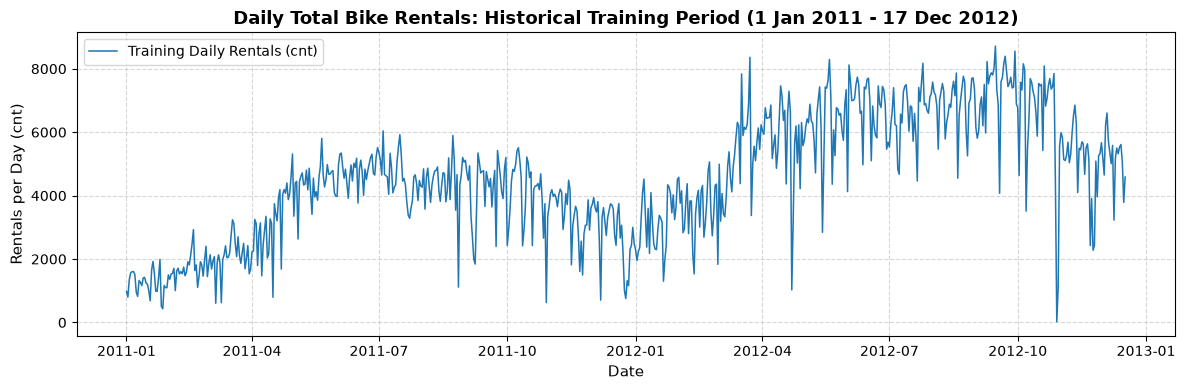

In [6]:
# ---------------------------------------------------------
# Part 3 Code (Step 2): Historical Training Series Time Plot
# ---------------------------------------------------------

# Note: We plot ONLY the training set to strictly prevent visual inspection of future test data
plt.figure(figsize=(12, 4))
plt.plot(train.index, train.values, color="tab:blue", linewidth=1.1, label="Training Daily Rentals (cnt)")
plt.title("Daily Total Bike Rentals: Historical Training Period (1 Jan 2011 - 17 Dec 2012)", fontsize=13, fontweight="bold")
plt.xlabel("Date", fontsize=11)
plt.ylabel("Rentals per Day (cnt)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


In [7]:
# ---------------------------------------------------------
# Part 3 Code (Step 3): Day-of-Week Summary Table (Training Data Only)
# ---------------------------------------------------------

# Define calendar weekday order starting from Monday to Sunday as prescribed
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Group training counts by weekday name and compute average daily rentals and number of observed days
dow = (
    train.groupby(train.index.day_name())
    .agg(mean_rentals=("mean"), n_days=("count"))
    .reindex(weekday_order)
)

# Round mean rentals to 1 decimal place
dow["mean_rentals"] = dow["mean_rentals"].round(1)

# Display the summary table
display(dow)

# Identify highest and lowest weekday averages and their difference
hi_day, lo_day = dow["mean_rentals"].idxmax(), dow["mean_rentals"].idxmin()
hi_val, lo_val = dow.loc[hi_day, "mean_rentals"], dow.loc[lo_day, "mean_rentals"]
diff = hi_val - lo_val

print(f"Highest mean weekday: {hi_day} with {hi_val:.1f} rentals/day")
print(f"Lowest mean weekday:  {lo_day} with {lo_val:.1f} rentals/day")
print(f"Difference (Peak - Trough): {diff:.1f} rentals/day")


,mean_rentals,n_days
dteday,,
Monday,4386.9,103
Tuesday,4534.7,102
Wednesday,4581.8,102
Thursday,4697.6,102
Friday,4716.4,102
Saturday,4608.9,103
Sunday,4276.2,103


Highest mean weekday: Friday with 4716.4 rentals/day
Lowest mean weekday:  Sunday with 4276.2 rentals/day
Difference (Peak - Trough): 440.2 rentals/day


### Inference vs. Prediction

**Does this support our expectation?** Partly. Friday has the highest mean (4,716.4), while Sunday has the lowest (4,276.2), with a difference of 440.2 rentals. We can also see that rentals generally increase from Monday to Friday. However, Saturday (4,608.9) still has more rentals than Monday, Tuesday, and Wednesday, so weekends are not necessarily less busy.


- **Inference:** What patterns can we observe from past rentals? We answer this by looking at and interpreting our training data.
- **Prediction:** How accurately can our SARIMA model predict the next 14 days of rentals? We answer this by comparing its predictions against the actual values in our unseen test data.

## Part 4: SARIMA Model

We use SARIMA(1,1,1)(1,0,1,7), a teaching specification (not claimed to be the best model) that learns from past values, day-to-day changes, and past errors, with a 7-day weekly seasonal structure that does not prove weekly seasonality exists.

## Part 5: 

### Workflow:
1. Fit `SARIMAX(train, order=(1,1,1), seasonal_order=(1,0,1,7), trend="n")` using maximum likelihood estimation (`maxiter=500`).
2. Verify numerical convergence via `mle_retvals['converged']`.
3. Generate 14-step out-of-sample forecast and 95% prediction intervals (`alpha=0.05`).
4. Construct the **Naive Weekly Baseline** by tiling the final training week (11–17 December 2012) twice.
5. Export the required submission file `test_predictions.csv`.


In [8]:
# ---------------------------------------------------------
# Part 5 Code (Step 1): Fit the Prescribed SARIMAX Model
# ---------------------------------------------------------

# Instantiate SARIMAX on training data with prescribed parameters
model = SARIMAX(
    train,
    order=(1, 1, 1),              # Non-seasonal: p=1, d=1, q=1
    seasonal_order=(1, 0, 1, 7),  # Seasonal: P=1, D=0, Q=1, s=7
    trend="n"                     # No deterministic trend/constant
)

# Fit model using Maximum Likelihood Estimation; measure execution time
start_fit = time()
fitted = model.fit(disp=False, maxiter=500)
fit_time = time() - start_fit

# Check optimizer convergence status
converged = fitted.mle_retvals.get("converged")
print(f"Model fitting completed in {fit_time:.2f} seconds.")
print("Optimizer Converged:", converged)

# Assert convergence before proceeding
assert converged, "Convergence is False! Do not interpret un-converged model."

# Display full statistical estimation summary
print(fitted.summary())


Model fitting completed in 1.21 seconds.
Optimizer Converged: True
                                     SARIMAX Results                                     
Dep. Variable:                               cnt   No. Observations:                  717
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood               -5889.959
Date:                           Sun, 15 Nov 2026   AIC                          11789.919
Time:                                   19:21:26   BIC                          11812.787
Sample:                               01-01-2011   HQIC                         11798.749
                                    - 12-17-2012                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3361      0.033     10.211      0.000 

In [51]:
# ---------------------------------------------------------
# Part 5 Code (Step 2): Generate 14-Day Forecast & Build Weekly Baseline
# ---------------------------------------------------------

# Generate 14-step out-of-sample forecast (for 18-31 Dec 2012)
fc = fitted.get_forecast(steps=14)

# Extract 95% nominal prediction intervals (alpha = 0.05 leaves 2.5% in each tail)
ci = fc.conf_int(alpha=0.05)

# Weekly Baseline: Repeat the final 7 days of training (11-17 Dec 2012) twice
# 18-24 Dec uses 11-17 Dec; 25-31 Dec ALSO uses 11-17 Dec (no test data leakage)
baseline = np.tile(train.iloc[-7:].to_numpy(), 2)

# Compile results table with all required columns
results = pd.DataFrame({
    "actual_cnt": test,
    "predicted_cnt": fc.predicted_mean,
    "baseline_cnt": baseline,
    "lower_95": ci.iloc[:, 0],
    "upper_95": ci.iloc[:, 1]
})

# Assert dates match test index exactly
assert results.index.equals(test.index), "Assertion Failed: Forecast dates do not match test index!"

# Compute absolute error: |actual - predicted|
results["absolute_error"] = abs(results.actual_cnt - results.predicted_cnt)

# Export submission artifact test_predictions.csv
results.rename_axis("date").to_csv("test_predictions.csv")
print("Saved 'test_predictions.csv' successfully (14 rows).")

# Display complete 14-day results table rounded to 1 decimal place
results.round(1)


Saved 'test_predictions.csv' successfully (14 rows).


,actual_cnt,predicted_cnt,baseline_cnt,lower_95,upper_95,absolute_error
2012-12-18,5557,4751.9,5501,2981.5,6522.4,805.1
2012-12-19,5267,5081.4,5319,3158.4,7004.4,185.6
2012-12-20,4128,5001.8,5532,3036.0,6967.6,873.8
2012-12-21,3623,5044.8,5611,3057.4,7032.3,1421.8
2012-12-22,1749,5011.9,5047,3008.2,7015.5,3262.9
2012-12-23,1787,4564.8,3786,2546.8,6582.9,2777.8
2012-12-24,920,4797.9,4585,2766.1,6829.8,3877.9
2012-12-25,1013,4797.7,5501,2740.7,6854.7,3784.7
2012-12-26,441,5055.1,5319,2980.4,7129.9,4614.1
2012-12-27,2114,4962.3,5532,2872.1,7052.6,2848.3


## Part 6: Evaluate and Explain the Forecasts

### Evaluation Tasks:
1. Compute **Mean Absolute Error (MAE)** for SARIMA and the Baseline over all 14 test days:
   $$\text{MAE} = \frac{1}{14} \sum_{i=1}^{14} |\text{actual}_i - \text{forecast}_i|$$
2. Inspect test residuals ($e_t = \text{actual}_t - \text{predicted}_t$).
3. Visualize actual rentals against SARIMA (with 95% prediction interval) and baseline.
4. Examine the first 5 test dates and explain the largest absolute error.
5. Compare prediction interval widths on Day 1 vs. Day 14 and explain operational implications.


In [52]:
# ---------------------------------------------------------
# Part 6 Code (Step 1): Calculate MAE & Verification Checks
# ---------------------------------------------------------

# Compute Mean Absolute Error for SARIMA and Baseline across all 14 test dates
mae_sarima = (results.actual_cnt - results.predicted_cnt).abs().mean()
mae_base = (results.actual_cnt - results.baseline_cnt).abs().mean()

# Present two-row comparison table: Method | MAE
mae_table = pd.DataFrame({
    "Method": ["SARIMA(1,1,1)(1,0,1,7)", "Weekly baseline (11-17 Dec repeated)"],
    "MAE": [round(mae_sarima, 1), round(mae_base, 1)]
})
display(mae_table)

# Verification checks on predictions and interval coverage
print(f"Negative SARIMA predictions: {(results.predicted_cnt < 0).sum()} (0 is valid)")
print(f"Negative lower bounds: {(results.lower_95 < 0).sum()} (lower bound can mathematically dip below 0)")

# Check empirical coverage: how many actual test counts fall within nominal 95% interval
coverage = ((results.actual_cnt >= results.lower_95) & (results.actual_cnt <= results.upper_95)).sum()
print(f"Actual counts within nominal 95% interval: {coverage} of 14 ({coverage/14*100:.1f}%)")


,Method,MAE
0,"SARIMA(1,1,1)(1,0,1,7)",2482.5
1,Weekly baseline (11-17 Dec repeated),2522.4


Negative SARIMA predictions: 0 (0 is valid)
Negative lower bounds: 0 (lower bound can mathematically dip below 0)
Actual counts within nominal 95% interval: 6 of 14 (42.9%)


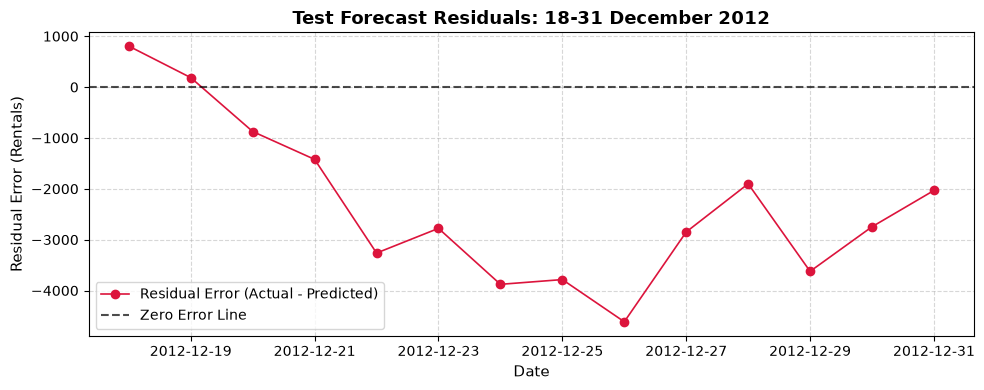

In [11]:
# ---------------------------------------------------------
# Part 6 Code (Step 2): Test Forecast Residuals Plot
# ---------------------------------------------------------

# Residual = Actual count - Predicted count
residuals = results["actual_cnt"] - results["predicted_cnt"]

plt.figure(figsize=(10, 4))
plt.plot(results.index, residuals, marker="o", color="crimson", linewidth=1.2, label="Residual Error (Actual - Predicted)")
plt.axhline(0, color="black", linestyle="--", alpha=0.7, label="Zero Error Line")
plt.title("Test Forecast Residuals: 18-31 December 2012", fontsize=13, fontweight="bold")
plt.ylabel("Residual Error (Rentals)", fontsize=11)
plt.xlabel("Date", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()


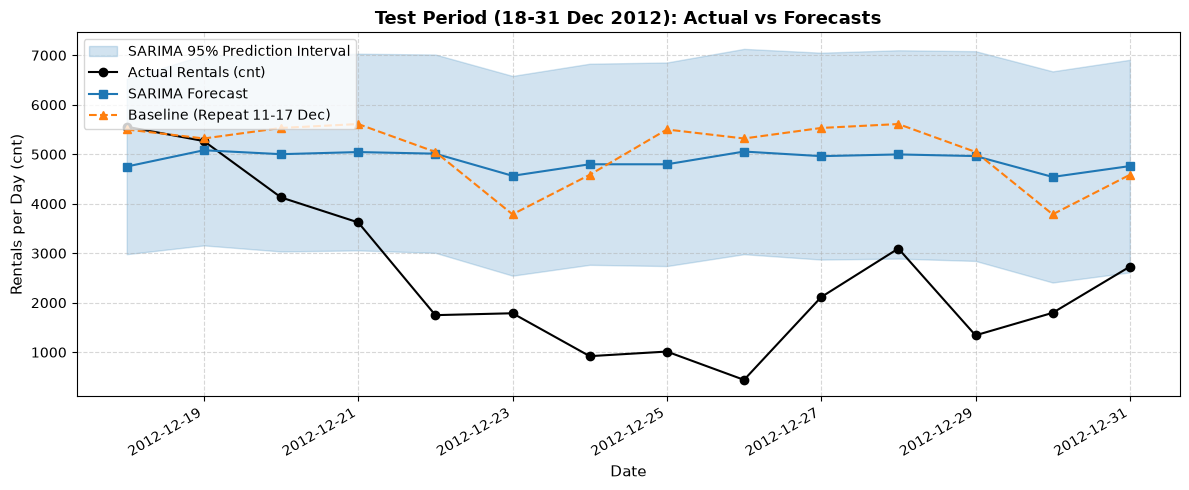

In [12]:
# ---------------------------------------------------------
# Part 6 Code (Step 3): Forecast Comparison Plot with Shaded 95% Prediction Interval
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

# Shade nominal 95% prediction interval
ax.fill_between(
    results.index,
    results.lower_95,
    results.upper_95,
    color="tab:blue",
    alpha=0.2,
    label="SARIMA 95% Prediction Interval"
)

# Plot actual counts, SARIMA forecasts, and baseline forecasts
ax.plot(results.index, results.actual_cnt, marker="o", color="black", linewidth=1.5, label="Actual Rentals (cnt)")
ax.plot(results.index, results.predicted_cnt, marker="s", color="tab:blue", linewidth=1.5, label="SARIMA Forecast")
ax.plot(results.index, results.baseline_cnt, marker="^", color="tab:orange", linestyle="--", linewidth=1.5, label="Baseline (Repeat 11-17 Dec)")

ax.set_title("Test Period (18-31 Dec 2012): Actual vs Forecasts", fontsize=13, fontweight="bold")
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Rentals per Day (cnt)", fontsize=11)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.5)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [55]:
# ---------------------------------------------------------
# Part 6 Code (Step 4): First Five Test Dates & Largest Error Analysis
# ---------------------------------------------------------

# Extract the first 5 test dates and attach weekday names for operational context
first5 = results.head(5).copy()
first5.insert(0, "weekday", first5.index.day_name())
display(first5.round(1))

# Identify the date with the maximum absolute error among the first five dates
max_err_date = first5["absolute_error"].idxmax()
max_err_val = first5.loc[max_err_date, "absolute_error"]
max_err_day = first5.loc[max_err_date, "weekday"]
actual_val = first5.loc[max_err_date, "actual_cnt"]
pred_val = first5.loc[max_err_date, "predicted_cnt"]

print(f"Largest absolute error in first 5 dates: {max_err_date.date()} ({max_err_day})")
print(f"Predicted: {pred_val:.1f} | Actual: {actual_val:.0f} | Absolute Error: {max_err_val:.1f} rentals")


,weekday,actual_cnt,predicted_cnt,baseline_cnt,lower_95,upper_95,absolute_error
2012-12-18,Tuesday,5557,4751.9,5501,2981.5,6522.4,805.1
2012-12-19,Wednesday,5267,5081.4,5319,3158.4,7004.4,185.6
2012-12-20,Thursday,4128,5001.8,5532,3036.0,6967.6,873.8
2012-12-21,Friday,3623,5044.8,5611,3057.4,7032.3,1421.8
2012-12-22,Saturday,1749,5011.9,5047,3008.2,7015.5,3262.9


Largest absolute error in first 5 dates: 2012-12-22 (Saturday)
Predicted: 5011.9 | Actual: 1749 | Absolute Error: 3262.9 rentals


### Explanation of the Largest Error in First 5 Test Dates:
- **Date:** Saturday, December 22, 2012
- **Absolute Error:** **3,262.9 rentals** (Predicted: **5,011.9** vs Actual: **1,749**)
- **Why did this happen?**
  - SARIMA learned from historical training data that Saturdays have high rental activity (Saturday training mean: **4,608.9 rentals**) and projected high demand (**5,011.9 rentals**).
  - However, the actual count on December 22, 2012 was **1,749 rentals**, which was far below the forecast. This lower volume is consistent with the pre-Christmas holiday period, though the specific cause was not tested.
  - Because our model is univariate and purely based on historical counts, it does not incorporate holiday schedules or external factors.

In [56]:
# ---------------------------------------------------------
# Part 6 Code (Step 5): Prediction Interval Width: Day 1 vs. Day 14
# ---------------------------------------------------------

# Extract Day 1 (2012-12-18) and Day 14 (2012-12-31) bounds
widths = results.iloc[[0, 13]][["lower_95", "upper_95"]].copy()

# Compute width: width = upper_95 - lower_95
widths["width"] = widths["upper_95"] - widths["lower_95"]
widths.index = ["Day 1 (" + str(results.index[0].date()) + ")", "Day 14 (" + str(results.index[13].date()) + ")"]

# Display bounds and width table rounded to 1 decimal place
display(widths.round(1))

w1 = widths.loc[widths.index[0], "width"]
w14 = widths.loc[widths.index[1], "width"]
diff_w = w14 - w1
print(f"Day 1 Width:  {w1:.1f} rentals")
print(f"Day 14 Width: {w14:.1f} rentals")
print(f"Interval expansion: Day 14 is wider by {diff_w:.1f} rentals ({diff_w/w1*100:.1f}% increase)")


,lower_95,upper_95,width
Day 1 (2012-12-18),2981.5,6522.4,3540.9
Day 14 (2012-12-31),2613.7,6909.1,4295.3


Day 1 Width:  3540.9 rentals
Day 14 Width: 4295.3 rentals
Interval expansion: Day 14 is wider by 754.5 rentals (21.3% increase)
